In [57]:
import random
import time
import warnings

import numpy as np
import pandas as pd
import scipy
from scipy.optimize import linprog, OptimizeWarning

# Fixed seed so every run of this notebook generates the same random LPs (reproducible results)
SEED = 620
random.seed(SEED)
np.random.seed(SEED)

# Silence the repeated deprecation / rank warnings so the benchmark output stays readable
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=OptimizeWarning)

METHOD = "highs-ds"

## Creating a wrapper function
This was done for simplicity
I also copied the parameters and results from the docs

In [58]:
def simplex(c, A_ub=None, b_ub=None, A_eq=None, b_eq=None, bounds=None):
    """
    Linear programming: minimize a linear objective function subject to linear equality and inequality constraints using the tableau-based simplex method.

    Parameters
    ----------
    c : 1-D array

        The coefficients of the linear objective function to be minimized.
    A_ub
    2-D array, optional

        The inequality constraint matrix. Each row of A_ub specifies the coefficients of a linear inequality constraint on x.
    b_ub
    1-D array, optional

        The inequality constraint vector. Each element represents an upper bound on the corresponding value of A_ub @ x.
    A_eq
    2-D array, optional

        The equality constraint matrix. Each row of A_eq specifies the coefficients of a linear equality constraint on x.
    b_eq
    1-D array, optional

        The equality constraint vector. Each element of A_eq @ x must equal the corresponding element of b_eq.
    bounds
    sequence, optional

        A sequence of (min, max) pairs for each element in x, defining the minimum and maximum values of that decision variable. Use None to indicate that there is no bound. By default, bounds are (0, None) (all decision variables are non-negative). If a single tuple (min, max) is provided, then min and max will serve as bounds for all decision variables.
    callback
    callable, optional

    Callback function to be executed once per iteration.

    Returns
    -------
    resOptimizeResult

    A scipy.optimize.OptimizeResult consisting of the fields:

    x1-D array

        The values of the decision variables that minimizes the objective function while satisfying the constraints.
    funfloat

        The optimal value of the objective function c @ x.
    slack1-D array

        The (nominally positive) values of the slack variables, b_ub - A_ub @ x.
    con1-D array

        The (nominally zero) residuals of the equality constraints, b_eq - A_eq @ x.
    successbool

        True when the algorithm succeeds in finding an optimal solution.
    statusint

        An integer representing the exit status of the algorithm.

        0 : Optimization terminated successfully.

        1 : Iteration limit reached.

        2 : Problem appears to be infeasible.

        3 : Problem appears to be unbounded.

        4 : Numerical difficulties encountered.
    messagestr

        A string descriptor of the exit status of the algorithm.
    nitint

        The total number of iterations performed in all phases.


    """
    # HiGHS presolve can solve small LPs before any pivot happens; turn it off so nit counts real simplex pivots
    options = {"presolve": False} if METHOD == "highs-ds" else None
    return linprog(c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq, bounds=bounds, method=METHOD, options=options)

## Testing the function
Using the example from the lecture slides

In [59]:
c = [7, 4, 6, 1]

A_eq = [[1, 2, -1, -1],
        [-1, -5, 2, 3]]
b_eq = [1, 1]

A_ub = [[-1, 0, 0, 0],
        [0, -1, 0, 0],
        [0, 0, -1, 0],
        [0, 0, 0, -1]]
b_ub = [0, 0, 0, 0]

simplex(
    c=c,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq
)

        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: 14.999999999999998
              x: [ 2.000e+00  0.000e+00  0.000e+00  1.000e+00]
            nit: 2
          lower:  residual: [ 2.000e+00  0.000e+00  0.000e+00  1.000e+00]
                 marginals: [ 0.000e+00  2.000e+00  9.000e+00  0.000e+00]
          upper:  residual: [       inf        inf        inf        inf]
                 marginals: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
          eqlin:  residual: [ 0.000e+00  0.000e+00]
                 marginals: [ 1.100e+01  4.000e+00]
        ineqlin:  residual: [ 2.000e+00  0.000e+00  0.000e+00  1.000e+00]
                 marginals: [-0.000e+00 -0.000e+00 -0.000e+00 -0.000e+00]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

This is the same result from the lecture, so it seems to be working.

## creating a function to generate inputs

this function will generate the appropriate matricies for the simplex algorithm
based on size m and n

this function guarantees feasible solutions

some notes:
 - When I originally wrote this function, it generated a b_eq matrix of all 1's (similar to the lecture), and the c matrix contained random integers from -100 to 100
 - When m>n the system A_eq*x=b_eq with m random equations and only n unknowns is almost surely inconsistent (an overdetermined system has a solution with probability ~0 for random coefficients). And even when consistent, combined with x>=0 the feasible set was almost certainly empty.
 - to fix this, the b_eq matrix was changed to guarantee feasibility by deriving b_eq from a know point x>=0.
 - with this change, the solutions typically became unbounded for small m
 - the solution was now to make c non-negative so that the objective is bounded below by zero.

 This was tricky to get straight. Initially when I ran the benchmark, there were some results that finished very quicky (essentially all results where m>n), because the algorithm terminated early. With these changes, I was able to get consistent results.

In [60]:
import random
def create_matrix(m_rows, n_cols):
    c = [random.randint(0, 100) for _ in range(n_cols)]
    A_eq = [[random.randint(-100, 100) for _ in range(n_cols)] for _ in range(m_rows)]
    # generate a known-feasible b_eq from a random nonnegative point
    x0 = [random.uniform(0, 10) for _ in range(n_cols)]
    b_eq = [sum(a * x for a, x in zip(row, x0)) for row in A_eq]
    A_ub = [[-1 if i == j else 0 for j in range(n_cols)] for i in range(n_cols)]
    b_ub = [0 for _ in range(n_cols)]
    return c, A_eq, b_eq, A_ub, b_ub


## another worked example with the newly generated matricies

In [61]:
c, A_eq, b_eq, A_ub, b_ub = create_matrix(m_rows=2, n_cols=4)
print(c)
print(A_eq)
print(b_eq)
print(A_ub)
print(b_ub)
simplex(
    c=c,
    A_ub=A_ub,
    b_ub=b_ub,
    A_eq=A_eq,
    b_eq=b_eq
)

[28, 55, 64, 60]
[[55, 50, 72, -79], [92, 86, 99, 23]]
[680.1998983562731, 1194.36969070743]
[[-1, 0, 0, 0], [0, -1, 0, 0], [0, 0, -1, 0], [0, 0, 0, -1]]
[0, 0, 0, 0]


        message: Optimization terminated successfully. (HiGHS Status 7: Optimal)
        success: True
         status: 0
            fun: 382.8326533217117
              x: [ 1.289e+01  0.000e+00  0.000e+00  3.647e-01]
            nit: 2
          lower:  residual: [ 1.289e+01  0.000e+00  0.000e+00  3.647e-01]
                 marginals: [ 0.000e+00  2.802e+01  4.119e+01  0.000e+00]
          upper:  residual: [       inf        inf        inf        inf]
                 marginals: [ 0.000e+00  0.000e+00  0.000e+00  0.000e+00]
          eqlin:  residual: [ 0.000e+00  0.000e+00]
                 marginals: [-5.714e-01  6.460e-01]
        ineqlin:  residual: [ 1.289e+01  0.000e+00  0.000e+00  3.647e-01]
                 marginals: [-0.000e+00 -0.000e+00 -0.000e+00 -0.000e+00]
 mip_node_count: 0
 mip_dual_bound: 0.0
        mip_gap: 0.0

## use this cell to generate the benchmark data
By default this runs only the 24 problem sizes the assignment asks for
(n = 4, 10, 20, 30, 40, 50 and m = 2, 6, 10, 14) and takes about a minute.
The full sweep that produced `benchmark_results2.csv` (n = 4..100, m = 2..30) is in the comment below (~20+ min).

Changes from the first version:
- timing uses `time.perf_counter()` (high resolution). `time.process_time()` only ticks every ~15.6 ms on Windows,
  which is slower than one solve, so the old times were mostly 0 or 1 tick.
- each LP is solved `timing_repeats` times and the median time is kept, to reduce noise
- failed solves are **counted** (infeasible / unbounded / other) instead of silently retried
- the final cost and the number of nonzero variables in the solution are recorded
- a cap on attempts so the loop can never run forever

In [ ]:
# Problem sizes required by the assignment (24 combinations)
N_VALUES = [4, 10, 20, 30, 40, 50]
M_VALUES = [2, 6, 10, 14]
file_name = "report_default"

# Full sweep (used for benchmark_results2.csv):
# N_VALUES = list(range(4, 101, 1))
# M_VALUES = list(range(2, 101, 1))
# file_name = str(N_VALUES[-1]) + "x" + str(M_VALUES[-1])

num_trials = 30                  # random LPs per (m, n)
timing_repeats = 5               # each LP is solved this many times; the median time is kept

file_name = METHOD + "_benchmark_results_" + file_name + ".csv"

rows = []
for n in N_VALUES:
    for m in M_VALUES:
        times, pivots, costs, nonzeros = [], [], [], []
        status_counts = {0: 0, 1: 0, 2: 0, 3: 0, 4: 0}
        while len(times) < num_trials:
            c, A_eq, b_eq, A_ub, b_ub = create_matrix(m_rows=m, n_cols=n)
            run_times = []
            for _ in range(timing_repeats):
                start = time.perf_counter()
                result = simplex(c=c, A_ub=A_ub, b_ub=b_ub, A_eq=A_eq, b_eq=b_eq)
                run_times.append(time.perf_counter() - start)
            status_counts[result.status] += 1
            if result.success:
                times.append(np.median(run_times))
                pivots.append(result.nit)
                costs.append(result.fun)
                nonzeros.append(int(np.sum(np.abs(result.x) > 1e-9)))
        rows.append({
            "m": m,
            "n": n,
            "trials_solved": len(times),
            "average_time": np.mean(times),
            "average_num_pivots": np.mean(pivots),
            "average_cost": np.mean(costs),
            "average_nonzero_vars": np.mean(nonzeros),
            "num_infeasible": status_counts[2],
            "num_unbounded": status_counts[3],
            "num_other_failures": status_counts[1] + status_counts[4],
        })
        print(f"m={m:>2}, n={n:>3}: {np.mean(pivots):6.2f} pivots, {np.mean(times) * 1000:7.3f} ms, "
              f"cost={np.mean(costs):10.2f}, nonzero vars={np.mean(nonzeros):5.2f}, "
              f"infeasible={status_counts[2]}, unbounded={status_counts[3]}")

df = pd.DataFrame(rows)
df.to_csv(file_name, index=False)


m= 2, n=  4:   2.07 pivots,   4.784 ms, cost=    601.64, nonzero vars= 2.00, infeasible=0, unbounded=0
m= 3, n=  4:   3.03 pivots,   6.798 ms, cost=    702.93, nonzero vars= 3.00, infeasible=0, unbounded=0
m= 4, n=  4:   4.00 pivots,   4.011 ms, cost=    911.77, nonzero vars= 4.00, infeasible=0, unbounded=0
m= 5, n=  4:   4.07 pivots,   3.497 ms, cost=   1063.94, nonzero vars= 4.00, infeasible=0, unbounded=0
m= 6, n=  4:   4.00 pivots,   3.411 ms, cost=   1035.79, nonzero vars= 4.00, infeasible=0, unbounded=0
m= 7, n=  4:   4.00 pivots,   4.275 ms, cost=    934.13, nonzero vars= 4.00, infeasible=0, unbounded=0
m= 8, n=  4:   4.07 pivots,   4.288 ms, cost=   1057.43, nonzero vars= 4.00, infeasible=0, unbounded=0
m= 9, n=  4:   4.03 pivots,   4.543 ms, cost=    858.94, nonzero vars= 4.00, infeasible=0, unbounded=0
m=10, n=  4:   4.00 pivots,   4.076 ms, cost=   1083.88, nonzero vars= 4.00, infeasible=0, unbounded=0
m=11, n=  4:   4.00 pivots,   4.403 ms, cost=    906.20, nonzero vars= 4.

## Results table for the report
One row per (n, m) pair: pivots, time, cost and how many variables are nonzero in the optimal solution.

In [63]:
results = pd.read_csv(METHOD + "_benchmark_results_report_default.csv")
report_table = results[["n", "m", "average_num_pivots", "average_time", "average_cost", "average_nonzero_vars",
                        "num_infeasible", "num_unbounded"]].copy()
report_table["average_time"] = report_table["average_time"] * 1000  # seconds -> ms
report_table = report_table.rename(columns={
    "average_num_pivots": "pivots",
    "average_time": "time (ms)",
    "average_cost": "cost",
    "average_nonzero_vars": "nonzero vars",
    "num_infeasible": "infeasible",
    "num_unbounded": "unbounded",
}).round(3)
report_table

,n,m,pivots,time (ms),cost,nonzero vars,infeasible,unbounded
0,4,2,2.067,4.800,601.644,2.0,0,0
1,4,6,4.000,4.058,1080.826,4.0,0,0
2,4,10,4.000,3.203,995.245,4.0,0,0
3,4,14,4.000,5.142,970.090,4.0,0,0
4,10,2,2.067,3.449,423.646,2.0,0,0
5,10,6,6.733,2.876,1625.470,6.0,0,0
6,10,10,10.200,2.969,2555.027,10.0,0,0
7,10,14,10.133,2.469,2488.738,10.0,0,0
8,20,2,2.167,3.751,332.051,2.0,0,0
9,20,6,7.133,2.540,1493.990,6.0,0,0


In [64]:
# Same data as grids (rows = n, columns = m) - easy to paste into the report
print("Average pivots")
print(results.pivot(index="n", columns="m", values="average_num_pivots").round(1), "\n")
print("Average time (ms)")
print((results.pivot(index="n", columns="m", values="average_time") * 1000).round(3), "\n")
print("Average number of nonzero variables at the optimum")
print(results.pivot(index="n", columns="m", values="average_nonzero_vars").round(1))

Average pivots
m    2    6     10    14
n                       
4   2.1  4.0   4.0   4.0
10  2.1  6.7  10.2  10.1
20  2.2  7.1  12.3  15.9
30  2.2  7.6  12.4  17.5
40  2.1  7.5  12.7  17.7
50  2.2  7.8  12.6  18.2 

Average time (ms)
m      2      6      10     14
n                             
4   4.800  4.058  3.203  5.142
10  3.449  2.876  2.969  2.469
20  3.751  2.540  2.897  2.678
30  2.590  4.646  4.247  4.275
40  2.621  2.194  2.186  2.432
50  2.425  2.255  2.619  2.574 

Average number of nonzero variables at the optimum
m    2    6     10    14
n                       
4   2.0  4.0   4.0   4.0
10  2.0  6.0  10.0  10.0
20  2.0  6.0  10.0  14.0
30  2.0  6.0  10.0  14.0
40  2.0  6.0  10.0  14.0
50  2.0  6.0  10.0  14.0


## Plots for the report: pivots and time vs n, one line per m
Plus time vs pivots (each pivot costs roughly the same, so this should be close to linear).

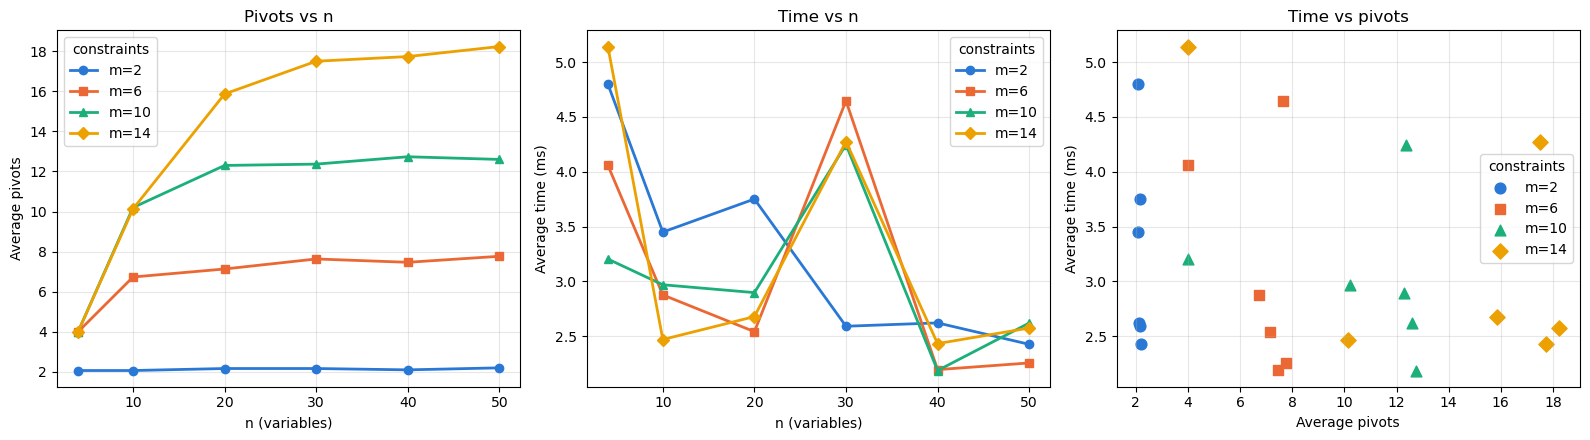

In [65]:
import matplotlib.pyplot as plt

results = pd.read_csv(METHOD + "_benchmark_results_report_default.csv")
# fixed color + marker per m, so lines are distinguishable without color too
M_STYLE = {2: ("#2a78d6", "o"), 6: ("#eb6834", "s"), 10: ("#1baf7a", "^"), 14: ("#eda100", "D")}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for m, group in results.groupby("m"):
    group = group.sort_values("n")
    color, marker = M_STYLE.get(m, ("#555555", "o"))
    axes[0].plot(group["n"], group["average_num_pivots"], color=color, marker=marker, lw=2, label=f"m={m}")
    axes[1].plot(group["n"], group["average_time"] * 1000, color=color, marker=marker, lw=2, label=f"m={m}")
    axes[2].scatter(group["average_num_pivots"], group["average_time"] * 1000, color=color, marker=marker,
                    s=60, label=f"m={m}")

axes[0].set(xlabel="n (variables)", ylabel="Average pivots", title="Pivots vs n")
axes[1].set(xlabel="n (variables)", ylabel="Average time (ms)", title="Time vs n")
axes[2].set(xlabel="Average pivots", ylabel="Average time (ms)", title="Time vs pivots")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(title="constraints")
plt.tight_layout()
plt.savefig("pivots_time_vs_n.png", dpi=200)
plt.show()

## Sparsity: how many variables are nonzero at the optimum?
Simplex stops at a vertex, and a basic feasible solution has at most m basic (nonzero) variables.
So with m = 2 and n = 50, at most 2 of the 50 variables can be nonzero.

In [66]:
results = pd.read_csv(METHOD + "_benchmark_results_report_default.csv")
results["max_possible_nonzero"] = results[["m", "n"]].min(axis=1)
results["fraction_nonzero"] = results["average_nonzero_vars"] / results["n"]
print(results[["n", "m", "average_nonzero_vars", "max_possible_nonzero", "fraction_nonzero"]].round(3).to_string(index=False))
print("\nNonzero variables never exceed min(m, n):",
      bool((results["average_nonzero_vars"] <= results["max_possible_nonzero"] + 1e-9).all()))

 n  m  average_nonzero_vars  max_possible_nonzero  fraction_nonzero
 4  2                   2.0                     2             0.500
 4  6                   4.0                     4             1.000
 4 10                   4.0                     4             1.000
 4 14                   4.0                     4             1.000
10  2                   2.0                     2             0.200
10  6                   6.0                     6             0.600
10 10                  10.0                    10             1.000
10 14                  10.0                    10             1.000
20  2                   2.0                     2             0.100
20  6                   6.0                     6             0.300
20 10                  10.0                    10             0.500
20 14                  14.0                    14             0.700
30  2                   2.0                     2             0.067
30  6                   6.0                     

### Note for the analysis: when m >= n the feasible region is a single point
`create_matrix` builds equality constraints `A_eq x = b_eq` with `b_eq = A_eq x0` for a random `x0 >= 0`.
With m >= n random equations in n unknowns, the only solution is `x0` itself, so the LP has exactly one feasible point.
That is why the pivot count stops growing at about n (e.g. n = 4 gives ~4 pivots for m = 6, 10, 14):
Simplex is just walking to that one point. Cases: (n=4, m=6/10/14) and (n=10, m=14).

## Edge cases: infeasible, unbounded, multiple optima, degeneracy
The random generator above is built to always be feasible and bounded, so these cases are shown with small hand-made LPs.
All are written as minimization (to maximize f, minimize -f). Status codes: 0 optimal, 2 infeasible, 3 unbounded.

In [67]:
def show(name, res):
    print(f"{name}\n  status={res.status} ({res.message})")
    if res.success:
        print(f"  x={np.round(res.x, 4)}, cost={res.fun:.4f}, pivots={res.nit}")
    print()

# 1) Infeasible: x1 + x2 <= 5 and x1 + x2 >= 10 can't both hold
show("1) Infeasible", simplex(c=[1, 1], A_ub=[[1, 1], [-1, -1]], b_ub=[5, -10]))

# 2) Bounded, then unbounded once a constraint is removed: maximize x1 + x2
show("2a) Bounded (x1 + x2 <= 4, x1 - x2 <= 2)", simplex(c=[-1, -1], A_ub=[[1, 1], [1, -1]], b_ub=[4, 2]))
show("2b) Remove x1 + x2 <= 4 -> unbounded", simplex(c=[-1, -1], A_ub=[[1, -1]], b_ub=[2]))

# 3) Multiple optimal solutions: objective x1 + x2 is parallel to the constraint x1 + x2 <= 4
res = simplex(c=[-1, -1], A_ub=[[1, 1], [1, 0]], b_ub=[4, 3])
show("3) Multiple optima (maximize x1 + x2, x1 + x2 <= 4, x1 <= 3)", res)
for v in ([0, 4], [3, 1], [1.5, 2.5]):
    print(f"  objective at {v} = {sum(v)}")
print("  -> every point on the edge from (0,4) to (3,1) is optimal\n")

# 4) Degeneracy: three constraints pass through the optimal vertex (1, 1) in 2-D,
#    so one basic variable is 0 at the optimum (more active constraints than needed)
res = simplex(c=[-1, -1], A_ub=[[1, 1], [1, 0], [0, 1]], b_ub=[2, 1, 1])
show("4) Degenerate vertex (x1 + x2 <= 2, x1 <= 1, x2 <= 1)", res)
print("  slacks:", np.round(res.slack, 4), "-> all three constraints are tight at (1, 1)")

1) Infeasible
  status=2 (The problem is infeasible. (HiGHS Status 8: model_status is Infeasible; primal_status is Infeasible))

2a) Bounded (x1 + x2 <= 4, x1 - x2 <= 2)
  status=0 (Optimization terminated successfully. (HiGHS Status 7: Optimal))
  x=[0. 4.], cost=-4.0000, pivots=1

2b) Remove x1 + x2 <= 4 -> unbounded
  status=3 (The problem is unbounded. (HiGHS Status 10: model_status is Unbounded; primal_status is Feasible))

3) Multiple optima (maximize x1 + x2, x1 + x2 <= 4, x1 <= 3)
  status=0 (Optimization terminated successfully. (HiGHS Status 7: Optimal))
  x=[0. 4.], cost=-4.0000, pivots=1

  objective at [0, 4] = 4
  objective at [3, 1] = 4
  objective at [1.5, 2.5] = 4.0
  -> every point on the edge from (0,4) to (3,1) is optimal

4) Degenerate vertex (x1 + x2 <= 2, x1 <= 1, x2 <= 1)
  status=0 (Optimization terminated successfully. (HiGHS Status 7: Optimal))
  x=[1. 1.], cost=-2.0000, pivots=2

  slacks: [0. 0. 0.] -> all three constraints are tight at (1, 1)


## visualizing the data
change the csv names to whatever results you want to check.
you dont need to run the previous cell if you already have the data.

the first few graphs show the duration (processor time)
the last few graph are exactly the same except they show number of pivots

I think we should add another graph showing time vs number of pivots (I expect it to be completely linear)

In [68]:
file_name = file_name

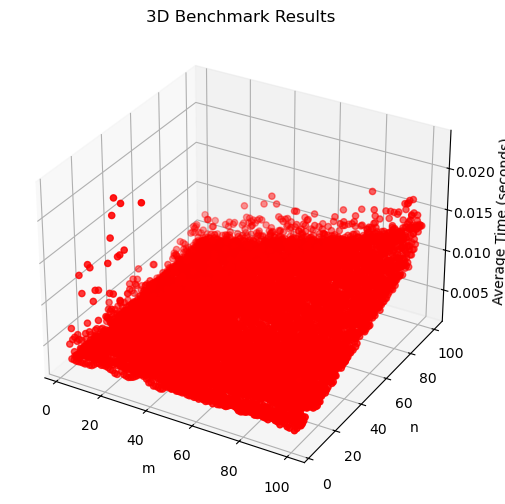

In [69]:
import pandas as pd
df = pd.read_csv(file_name)
df.head()

import matplotlib.pyplot as plt

#show a 3d plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df["m"], df["n"], df["average_time"], c='r', marker='o')
ax.set_xlabel("m")
ax.set_ylabel("n")
ax.set_zlabel("Average Time (seconds)")
ax.set_title("3D Benchmark Results")
plt.show()

C:\Users\jackm\AppData\Local\Temp\ipykernel_1616\1863311180.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


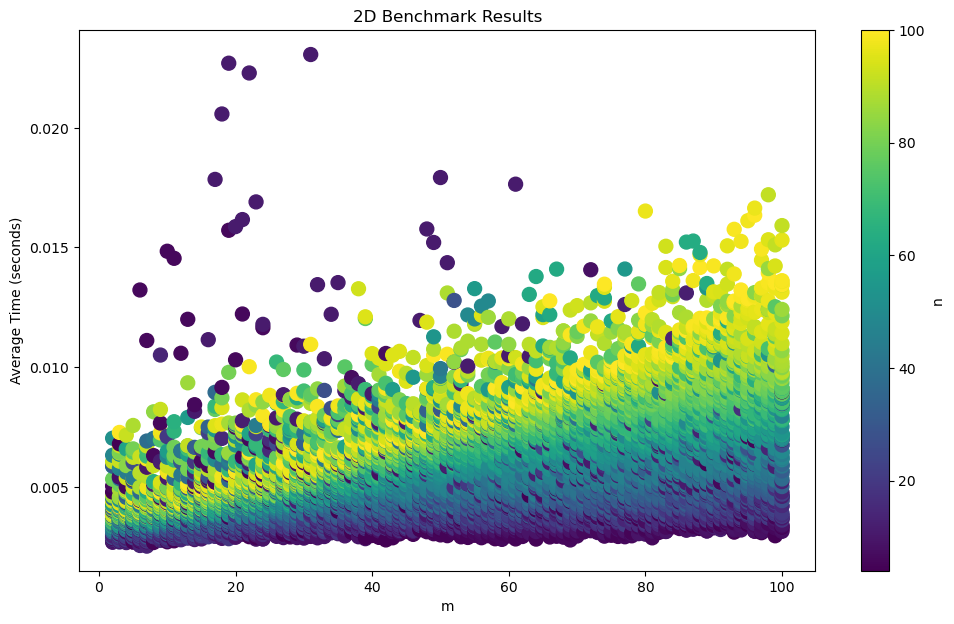

In [70]:
df = pd.read_csv(file_name)

import matplotlib.pyplot as plt


fig, ax = plt.subplots(figsize=(10, 6))
n_values = sorted(df["n"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

for m, group in df.groupby("m"):
    group = group.sort_values("average_time")          # largest time drawn last → on top
    ax.scatter(
        group["m"],
        group["average_time"],
        c=[color_map[n] for n in group["n"]],          # manual per-point colors
        s=100,
    )

from matplotlib.lines import Line2D

# Create a legend for the color map (n values)
# handles = [
#     Line2D([], [], marker="o", linestyle="", color=color_map[n], label=f"n={n}")
#     for n in n_values
# ]
#plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=2)

# Show a gradient color map for n values
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(n_values), vmax=max(n_values)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label="n")

fig.tight_layout()
ax.set_xlabel("m")
ax.set_ylabel("Average Time (seconds)")
ax.set_title("2D Benchmark Results")

fig.show()

C:\Users\jackm\AppData\Local\Temp\ipykernel_1616\768947425.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


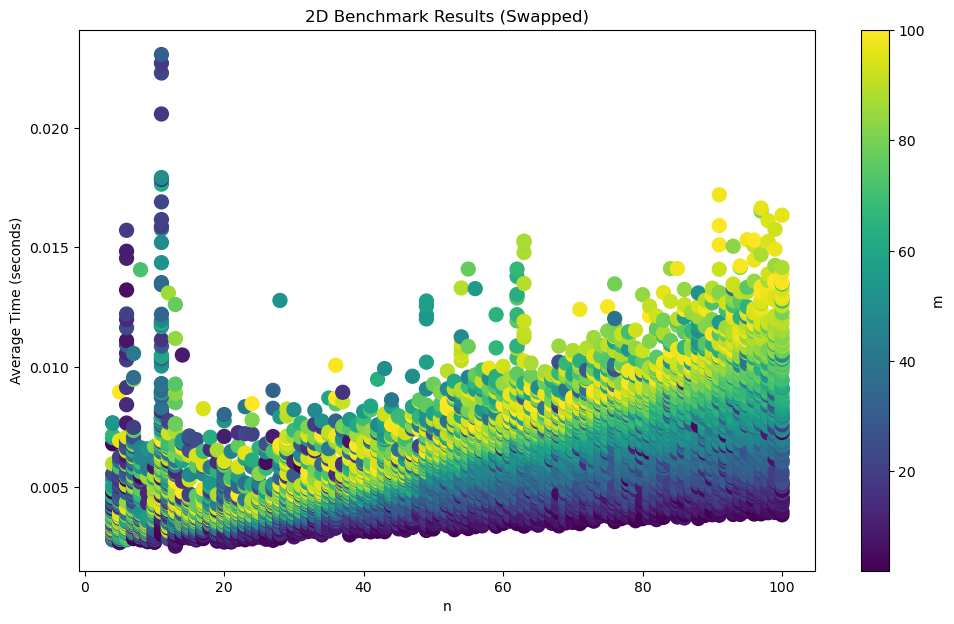

In [71]:
fig, ax = plt.subplots(figsize=(10, 6))
m_values = sorted(df["m"].unique())
color_map = {m: plt.cm.viridis(i / (len(m_values) - 1)) for i, m in enumerate(m_values)}

for n, group in df.groupby("n"):
    group = group.sort_values("average_time")          # largest time drawn last → on top
    ax.scatter(
        group["n"],
        group["average_time"],
        c=[color_map[m] for m in group["m"]],          # manual per-point colors
        s=100,
    )

# Create a legend for the color map (m values)
# handles = [
#     Line2D([], [], marker="o", linestyle="", color=color_map[m], label=f"m={m}")
#     for m in m_values
# ]
# ax.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=1)

# Show a gradient color map for m values
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(m_values), vmax=max(m_values)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label="m")

fig.tight_layout()
ax.set_xlabel("n")
ax.set_ylabel("Average Time (seconds)")
ax.set_title("2D Benchmark Results (Swapped)")

fig.show()

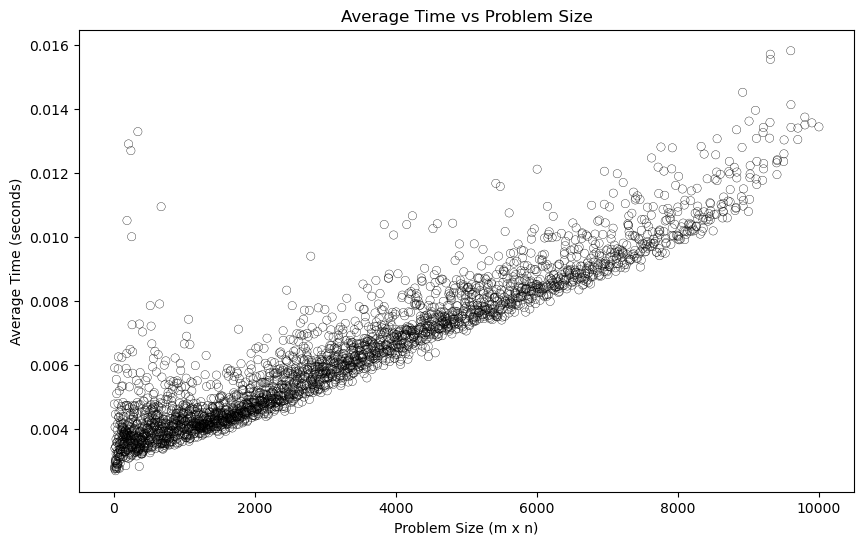

In [72]:
# plot average times for vs mxn (size of problem)
df=pd.read_csv(file_name)
plt.figure(figsize=(10, 6))

average_times = dict()

for r in df.itertuples():
    size = r.m * r.n
    value = r.average_time
    if size not in average_times:
        average_times[size] = []
    average_times[size].append(value)

# compute the average for each size
average_times = {size: sum(times) / len(times) for size, times in average_times.items()}

# plot the results
sizes = sorted(average_times.keys())
times = [average_times[size] for size in sizes]
plt.scatter(sizes, times, facecolors='none', edgecolors='black', linewidths=0.25)
plt.xlabel("Problem Size (m x n)")
plt.ylabel("Average Time (seconds)")
plt.title("Average Time vs Problem Size")

plt.show()

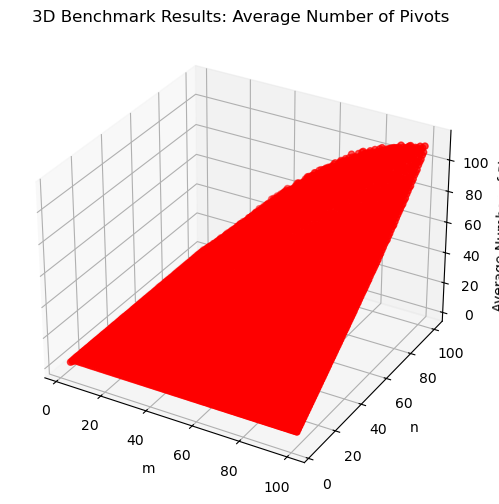

In [73]:
df = pd.read_csv(file_name)
df.head()

import matplotlib.pyplot as plt

#show a 3d plot
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df["m"], df["n"], df["average_num_pivots"], c='r', marker='o')
ax.set_xlabel("m")
ax.set_ylabel("n")
ax.set_zlabel("Average Number of Pivots")
ax.set_title("3D Benchmark Results: Average Number of Pivots")
plt.show()

C:\Users\jackm\AppData\Local\Temp\ipykernel_1616\336125875.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


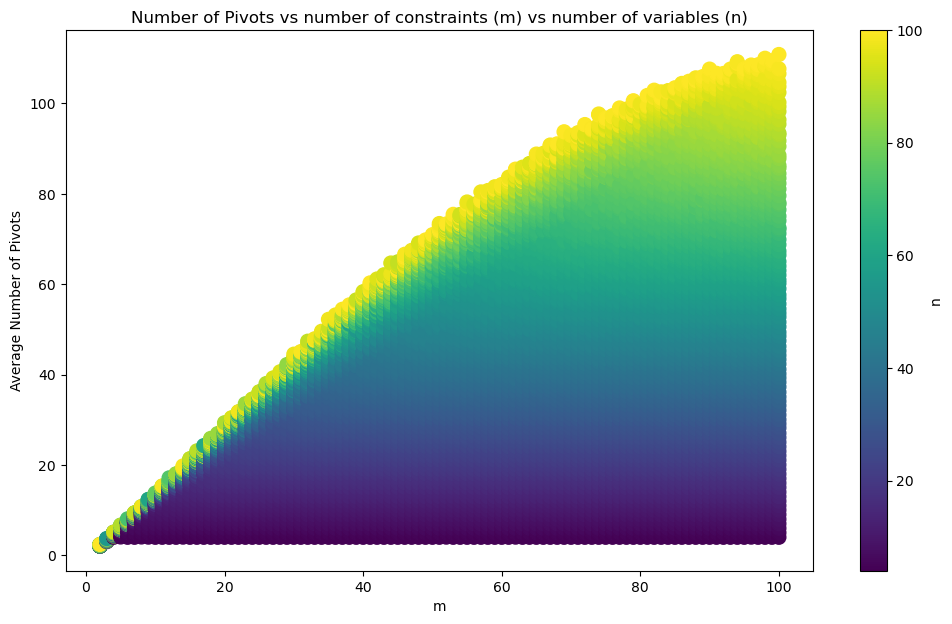

In [74]:
df = pd.read_csv(file_name)

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

n_values = sorted(df["n"].unique())
color_map = {n: plt.cm.viridis(i / (len(n_values) - 1)) for i, n in enumerate(n_values)}

for m, group in df.groupby("m"):
    group = group.sort_values("average_num_pivots")          # largest time drawn last → on top
    ax.scatter(
        group["m"],
        group["average_num_pivots"],
        c=[color_map[n] for n in group["n"]],          # manual per-point colors
        s=100,
    )



# Create a legend for the color map (n values)
# from matplotlib.lines import Line2D
# handles = [
#     Line2D([], [], marker="o", linestyle="", color=color_map[n], label=f"n={n}")
#     for n in n_values
# ]
# plt.legend(handles=handles, loc='center left', bbox_to_anchor=(1.02, 0.5), ncol=4)

# Show a gradient color map for n values
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(n_values), vmax=max(n_values)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label="n")


fig.tight_layout()
ax.set_xlabel("m")
ax.set_ylabel("Average Number of Pivots")
ax.set_title("Number of Pivots vs number of constraints (m) vs number of variables (n)")

fig.show()

C:\Users\jackm\AppData\Local\Temp\ipykernel_1616\1529968988.py:32: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


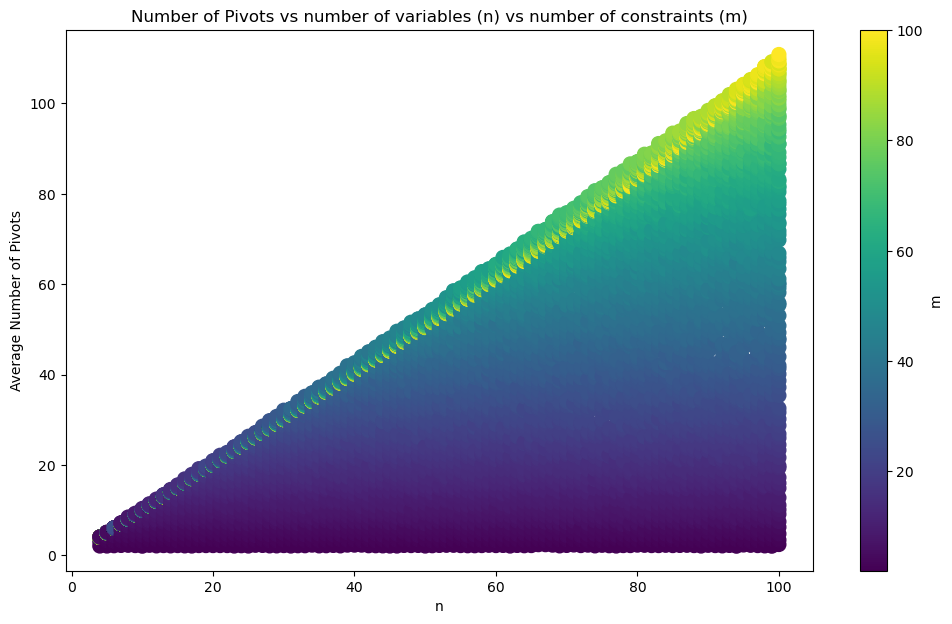

In [75]:
fig, ax = plt.subplots(figsize=(10, 6))
m_values = sorted(df["m"].unique())
color_map = {m: plt.cm.viridis(i / (len(m_values) - 1)) for i, m in enumerate(m_values)}

for n, group in df.groupby("n"):
    group = group.sort_values("average_num_pivots")          # largest time drawn last → on top
    ax.scatter(
        group["n"],
        group["average_num_pivots"],
        c=[color_map[m] for m in group["m"]],          # manual per-point colors
        s=100,
    )

# Create a legend for the color map (m   values)
# from matplotlib.lines import Line2D
# handles = [
#     Line2D([], [], marker="o", linestyle="", color=color_map[m], label=f"m={m}")
#     for m in n_values
# ]
# ax.legend(handles=handles, loc='upper left', ncol=2)

# Show a gradient color map for m values
sm = plt.cm.ScalarMappable(cmap=plt.cm.viridis, norm=plt.Normalize(vmin=min(m_values), vmax=max(m_values)))
sm.set_array([])
fig.colorbar(sm, ax=ax, label="m")

fig.tight_layout()
ax.set_xlabel("n")
ax.set_ylabel("Average Number of Pivots")
ax.set_title("Number of Pivots vs number of variables (n) vs number of constraints (m)")

fig.show()

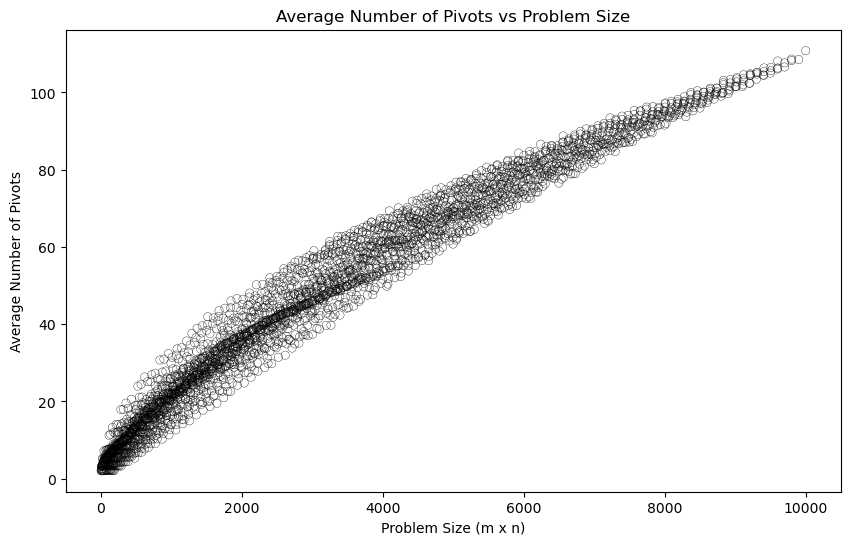

In [76]:
# plot average number of pivots for vs mxn (size of problem)
df=pd.read_csv(file_name)
plt.figure(figsize=(10, 6))

average_pivots = dict()

for r in df.itertuples():
    size = r.m * r.n
    time = r.average_num_pivots
    if size not in average_pivots:
        average_pivots[size] = []
    average_pivots[size].append(time)

# compute the average for each size
average_pivots = {size: sum(times) / len(times) for size, times in average_pivots.items()}

# plot the results
sizes = sorted(average_pivots.keys())
times = [average_pivots[size] for size in sizes]
plt.scatter(sizes, times, facecolors='none', edgecolors='black', linewidths=0.25)
plt.xlabel("Problem Size (m x n)")
plt.ylabel("Average Number of Pivots")
plt.title("Average Number of Pivots vs Problem Size")

plt.show()

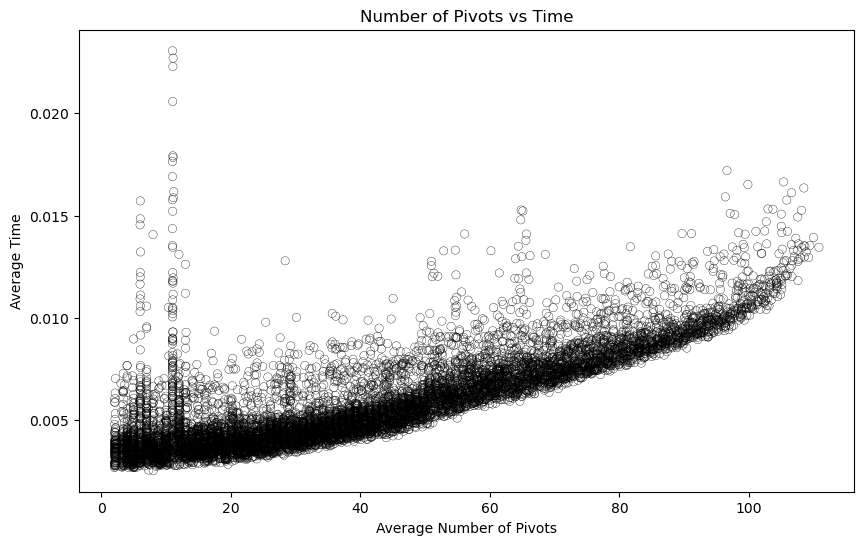

In [77]:
# plot number of pivots vs time

df = pd.read_csv(file_name)
plt.figure(figsize=(10, 6))
plt.scatter(df["average_num_pivots"], df["average_time"], facecolors='none', edgecolors='black', linewidths=0.25)
plt.xlabel("Average Number of Pivots")
plt.ylabel("Average Time")
plt.title("Number of Pivots vs Time")
plt.show()